# Stage 1 — CTC Validation with the GNW Mean-Field Interface

This notebook tests whether phase coordination improves S→W communication in the two-node GNW mean-field model from Stage 0. The rate/E-I dynamics call the shared `gnw_mean_field.py` interface; the Kuramoto-style phases are an added mechanism.

**Conditions**

- **A:** mutually coupled phases; S→W rate pathway is present and phase-gated.
- **B:** both phase oscillators are attracted to a shared rhythm; S→W rate pathway is cut.
- **C:** W phase is one-way dragged by S; S→W rate pathway is present and phase-gated.

The pilot selected stimulus drive 0.12, S→W gain 0.95, and gate strength 0.5 as a non-ceiling working point (A at K=1.5 ignited 4/5 pilot seeds). This is provisional; the scan reports the outcome over all K rather than assuming it generalizes. The notebook runs 50 paired seeds for each configuration and K. A same-mean fixed-weight control for A and C checks whether an effect comes from time-varying gating or simply stronger average coupling.

## Step 1 — imports and confirmatory settings

Do not change the stimulus or transfer curves during the primary K scan. The extension at the end varies stimulus strength to build the K × input parameter map.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'gnw_mean_field.py').exists()), None)
if project_root is None:
    raise RuntimeError('Run Jupyter from the repository or a subdirectory.')
sys.path.insert(0, str(project_root))
sys.path.insert(0, str(project_root / 'project_experiment'))

from stage0_two_node import DEFAULTS, simulate_stage0
from ctc_validation import _mutual_information_bits

K_values = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]  # rad/s
N_SEEDS = 50
seeds = np.arange(1, N_SEEDS + 1)
phase_gate = 0.5
stage1_params = {**DEFAULTS, 'stimulus_drive': 0.12, 'g_sw': 0.95,
                 'phase_gate_strength': phase_gate}
print(f'{len(K_values)} coupling values × {N_SEEDS} paired seeds; gate={phase_gate}')

6 coupling values × 50 paired seeds; gate=0.5


## Step 2 — define measurements

`R` is the PLV across the **whole stimulus interval**, so it measures whether the phase difference stays concentrated over multiple alpha cycles. MI is estimated between `r_S` and `r_W` during stimulation. Because these are autocorrelated time series, the notebook estimates a circular-shift null and reports raw and bias-corrected MI. Treat this MI as rate association, not proof of causal information transfer.

In [2]:
def _mi_with_shift_null(r_s, r_w, seed, bins=6, n_surrogates=30):
    raw = _mutual_information_bits(r_s, r_w, bins=bins)
    if len(r_s) < 40:
        return raw, 0.0, raw
    rng = np.random.default_rng(int(seed) + 500_000)
    low = max(10, int(0.1 * len(r_s)))
    high = max(low + 1, int(0.9 * len(r_s)))
    shifts = rng.integers(low, high, size=n_surrogates)
    null = np.array([_mutual_information_bits(r_s, np.roll(r_w, int(s)), bins=bins)
                     for s in shifts])
    bias = float(null.mean())
    return raw, bias, max(0.0, raw - bias)


def _record_trial(result, label, K, seed, gate_label, stim_on, stim_off):
    time_ms = result['time_ms']
    during = (time_ms >= stim_on) & (time_ms < stim_off)
    after = time_ms >= stim_off
    phase_delta = result['theta_w_rad'][during] - result['theta_s_rad'][during]
    R = float(abs(np.exp(1j * phase_delta).mean()))
    mi_raw, mi_null, mi_corrected = _mi_with_shift_null(
        result['r_s_hz'][during], result['r_w_hz'][during], seed
    )
    return {
        'condition': label, 'K_rad_s': K, 'seed': int(seed),
        'gate_strength': gate_label, 'R_PLV_during_stim': R,
        'MI_rates_raw_bits': mi_raw, 'MI_shift_null_bits': mi_null,
        'MI_rates_corrected_bits': mi_corrected,
        'W_ignited': bool(result['ignited']),
        'W_latency_ms': result['ignition_latency_ms'],
        'mean_rS_during_hz': float(result['r_s_hz'][during].mean()),
        'mean_rW_during_hz': float(result['r_w_hz'][during].mean()),
        'mean_rW_after_hz': float(result['r_w_hz'][after].mean()),
        'max_rW_hz': float(result['r_w_hz'].max()),
        'mean_gSW_during': float(result['g_sw_effective'][during].mean()),
    }

## Step 3 — run Experiment 1.1 (A/B/C × K × 50 seeds)

For A and C, each gated run is paired with a constant S→W gain equal to that trial's mean gated gain. B has no rate pathway, so it has no matched-link control. This is 1,500 simulations; the progress bar reports completion.

In [3]:
total_runs = len(K_values) * len(seeds) * 5  # A, B, C plus mean-matched controls for A and C
try:
    from tqdm.auto import tqdm
    progress = tqdm(total=total_runs, desc='CTC Stage 1.1', unit='run')
except ImportError:
    progress = None

trial_rows = []
for K in K_values:
    for seed in seeds:
        # A: mutual phase coupling plus phase-gated S→W rate pathway.
        run_A = simulate_stage0('A', seed=seed,
                                params={**stage1_params, 'phase_coupling_rad_s': K})
        trial_rows.append(_record_trial(run_A, 'A_dynamic_gate', K, seed, phase_gate,
                                        stage1_params['stim_on_ms'], stage1_params['stim_off_ms']))
        if progress is not None: progress.update(1)

        # B: common rhythm, but the S→W rate projection is cut by the model.
        run_B = simulate_stage0('B', seed=seed,
                                params={**stage1_params, 'phase_coupling_rad_s': K,
                                        'phase_gate_strength': 0.0})
        trial_rows.append(_record_trial(run_B, 'B_common_drive_no_link', K, seed, 0.0,
                                        stage1_params['stim_on_ms'], stage1_params['stim_off_ms']))
        if progress is not None: progress.update(1)

        # C: one-way phase drag with the same directed rate pathway.
        run_C = simulate_stage0('C', seed=seed,
                                params={**stage1_params, 'phase_coupling_rad_s': K})
        trial_rows.append(_record_trial(run_C, 'C_one_way_phase_drag', K, seed, phase_gate,
                                        stage1_params['stim_on_ms'], stage1_params['stim_off_ms']))
        if progress is not None: progress.update(1)

        # Mean-strength controls for A and C: fixed gain, matched within paired trial.
        for condition, dynamic_run in (('A', run_A), ('C', run_C)):
            during = (dynamic_run['time_ms'] >= stage1_params['stim_on_ms']) & (dynamic_run['time_ms'] < stage1_params['stim_off_ms'])
            matched_gain = float(dynamic_run['g_sw_effective'][during].mean())
            fixed = simulate_stage0(condition, seed=seed, params={
                **stage1_params, 'phase_coupling_rad_s': K,
                'phase_gate_strength': 0.0, 'g_sw': matched_gain,
            })
            trial_rows.append(_record_trial(fixed, f'{condition}_mean_matched_fixed', K, seed,
                                            phase_gate, stage1_params['stim_on_ms'], stage1_params['stim_off_ms']))
            if progress is not None: progress.update(1)

if progress is not None: progress.close()
stage1_trials = pd.DataFrame(trial_rows)
stage1_trials.to_csv(project_root / 'project_experiment' / 'stage1_ctc_trial_results.csv', index=False)
print(f'Completed {len(stage1_trials)} runs; saved paired trial data.')

CTC Stage 1.1:   0%|          | 0/1500 [00:00<?, ?run/s]

Completed 1500 runs; saved paired trial data.


## Step 4 — summarize synchronization, MI, and ignition

The summary keeps each K value separate. Do not pool K values into one gate-strength score: K is an experimental factor, and pooling can hide where A/B/C differ.

In [4]:
stage1_summary = stage1_trials.groupby(['condition', 'K_rad_s']).agg(
    n=('seed', 'count'),
    mean_R=('R_PLV_during_stim', 'mean'),
    sd_R=('R_PLV_during_stim', 'std'),
    mean_MI_corrected_bits=('MI_rates_corrected_bits', 'mean'),
    ignition_probability=('W_ignited', 'mean'),
    mean_latency_ms=('W_latency_ms', 'mean'),
    mean_rW_during_hz=('mean_rW_during_hz', 'mean'),
    mean_rW_after_hz=('mean_rW_after_hz', 'mean'),
    mean_peak_rW_hz=('max_rW_hz', 'mean'),
).reset_index()
display(stage1_summary.round(3))
stage1_summary.to_csv(project_root / 'project_experiment' / 'stage1_ctc_summary.csv', index=False)

# Paired-seed A-minus-B and A-minus-C differences at each K.
paired_rows = []
for K in K_values:
    a = stage1_trials[(stage1_trials.condition == 'A_dynamic_gate') & (stage1_trials.K_rad_s == K)].set_index('seed')
    for control in ('B_common_drive_no_link', 'C_one_way_phase_drag'):
        b = stage1_trials[(stage1_trials.condition == control) & (stage1_trials.K_rad_s == K)].set_index('seed')
        pair = a[['W_ignited', 'MI_rates_corrected_bits']].join(
            b[['W_ignited', 'MI_rates_corrected_bits']], lsuffix='_A', rsuffix='_control')
        for outcome in ('W_ignited', 'MI_rates_corrected_bits'):
            delta = (pair[f'{outcome}_A'].astype(float) - pair[f'{outcome}_control'].astype(float)).to_numpy()
            rng = np.random.default_rng(20261122 + int(K*100) + len(control))
            draws = rng.choice(delta, size=(3000, len(delta)), replace=True).mean(axis=1)
            paired_rows.append({
                'K_rad_s': K, 'control': control, 'outcome': outcome,
                'A_minus_control_mean': delta.mean(),
                'bootstrap_95ci_low': np.quantile(draws, .025),
                'bootstrap_95ci_high': np.quantile(draws, .975),
            })
paired_effects = pd.DataFrame(paired_rows)
print('Paired-seed contrasts (positive means A is higher):')
display(paired_effects.round(4))
paired_effects.to_csv(project_root / 'project_experiment' / 'stage1_ctc_paired_effects.csv', index=False)

,condition,K_rad_s,n,mean_R,sd_R,mean_MI_corrected_bits,ignition_probability,mean_latency_ms,mean_rW_during_hz,mean_rW_after_hz,mean_peak_rW_hz
0,A_dynamic_gate,0.0,50,0.968,0.011,0.043,0.42,84.238,18.217,10.839,20.787
1,A_dynamic_gate,0.5,50,0.971,0.022,0.078,0.50,99.400,18.593,11.155,21.083
2,A_dynamic_gate,1.0,50,0.969,0.038,0.100,0.58,96.207,18.933,11.437,21.331
3,A_dynamic_gate,1.5,50,0.964,0.051,0.131,0.68,98.206,19.224,11.640,21.532
4,A_dynamic_gate,2.0,50,0.957,0.063,0.142,0.82,108.268,19.467,11.778,21.756
5,A_dynamic_gate,3.0,50,0.945,0.082,0.173,0.90,90.178,19.840,11.921,22.194
6,A_mean_matched_fixed,0.0,50,0.968,0.011,0.387,0.34,52.176,18.222,11.008,20.394
7,A_mean_matched_fixed,0.5,50,0.971,0.022,0.395,0.38,42.947,18.593,11.162,20.893
8,A_mean_matched_fixed,1.0,50,0.969,0.038,0.397,0.48,55.000,18.928,11.301,21.347
9,A_mean_matched_fixed,1.5,50,0.964,0.051,0.406,0.54,48.741,19.216,11.420,21.737


Paired-seed contrasts (positive means A is higher):


C:\Windows\Temp\ipykernel_1548\1928192928.py:21: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  pair = a[['W_ignited', 'MI_rates_corrected_bits']].join(
C:\Windows\Temp\ipykernel_1548\1928192928.py:21: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  pair = a[['W_ignited', 'MI_rates_corrected_bits']].join(
C:\Windows\Temp\ipykernel_1548\1928192928.py:21: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  pair = a[['W_ignited', 'MI_rates_corrected_bits']].join(
C:\Windows\Temp\ipykernel_1548\1928192928.py:21: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'su

,K_rad_s,control,outcome,A_minus_control_mean,bootstrap_95ci_low,bootstrap_95ci_high
0,0.0,B_common_drive_no_link,W_ignited,0.4200,0.2800,0.5600
1,0.0,B_common_drive_no_link,MI_rates_corrected_bits,-0.2380,-0.2589,-0.2138
2,0.0,C_one_way_phase_drag,W_ignited,0.1000,-0.0200,0.2200
3,0.0,C_one_way_phase_drag,MI_rates_corrected_bits,-0.0921,-0.1256,-0.0576
4,0.5,B_common_drive_no_link,W_ignited,0.5000,0.3600,0.6400
5,0.5,B_common_drive_no_link,MI_rates_corrected_bits,-0.2025,-0.2232,-0.1790
6,0.5,C_one_way_phase_drag,W_ignited,0.0200,-0.1200,0.1600
7,0.5,C_one_way_phase_drag,MI_rates_corrected_bits,-0.0515,-0.0876,-0.0146
8,1.0,B_common_drive_no_link,W_ignited,0.5800,0.4400,0.7200
9,1.0,B_common_drive_no_link,MI_rates_corrected_bits,-0.1807,-0.2032,-0.1568


## Step 5 — Experiment 1.2: ignition probability versus R

Each point is one K value, with 50 trials contributing to its ignition probability. The curves only support a same-R comparison where the configurations' R ranges overlap. B's high R with no ignition is an explicit common-drive counterexample, not a failed simulation.

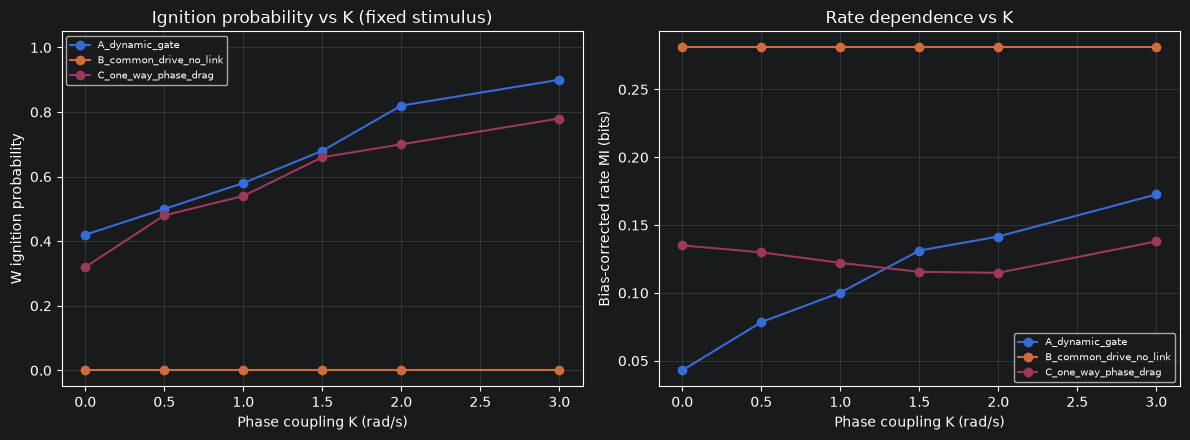

In [5]:
core = stage1_summary[stage1_summary.condition.isin([
    'A_dynamic_gate', 'B_common_drive_no_link', 'C_one_way_phase_drag'])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for condition, group in core.groupby('condition'):
    group = group.sort_values('K_rad_s')
    axes[0].plot(group['K_rad_s'], group['ignition_probability'], 'o-', label=condition)
    axes[1].plot(group['K_rad_s'], group['mean_MI_corrected_bits'], 'o-', label=condition)
axes[0].set(xlabel='Phase coupling K (rad/s)', ylabel='W ignition probability', ylim=(-.05, 1.05),
            title='Ignition probability vs K (fixed stimulus)')
axes[1].set(xlabel='Phase coupling K (rad/s)', ylabel='Bias-corrected rate MI (bits)',
            title='Rate dependence vs K')
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(project_root / 'project_experiment' / 'stage1_ctc_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()


## Step 6 — read the decision criteria

1. **Synchronization control:** if B reaches R values similar to A but has little MI and no W ignition, common drive can create synchrony without communicating the sensory response.
2. **One-way phase control:** if C has MI close to A but consistently lower ignition/response at matched R, that supports an additional benefit from reciprocal phase coordination. If C matches A on both, the model does not show that reciprocity is necessary.
3. **Causal contribution:** A should exceed both controls over a reproducible K range, with paired-seed intervals above zero and no ceiling firing. A-vs-fixed-mean controls distinguish dynamic timing from a larger average pathway.

MI here is a bias-corrected association measure on simulated rates; it is not by itself proof of directed information transfer. Treat the result as supporting or rejecting this model's CTC mechanism, not as a biological conclusion.

## Optional — build the K × stimulus parameter map

After the fixed-stimulus test, run this optional map with 30–50 seeds. It omits matched-weight controls to keep the map tractable; use it to locate candidate regions, then rerun the candidate region with all controls above.

In [6]:
# Set RUN_PARAMETER_MAP=True to run the optional wider map.
RUN_PARAMETER_MAP = False
stimulus_grid = [0.08, 0.10, 0.12, 0.14, 0.16]
map_seeds = np.arange(1, 31)
if RUN_PARAMETER_MAP:
    map_rows = []
    map_total = len(stimulus_grid) * len(K_values) * 3 * len(map_seeds)
    try:
        map_progress = tqdm(total=map_total, desc='K × stimulus map', unit='run')
    except NameError:
        map_progress = None
    for drive in stimulus_grid:
        for K in K_values:
            for condition in ('A', 'B', 'C'):
                for seed in map_seeds:
                    run = simulate_stage0(condition, seed=seed, params={
                        **stage1_params, 'stimulus_drive': drive,
                        'phase_coupling_rad_s': K,
                        'phase_gate_strength': 0.0 if condition == 'B' else phase_gate,
                    })
                    during = (run['time_ms'] >= stage1_params['stim_on_ms']) & (run['time_ms'] < stage1_params['stim_off_ms'])
                    delta = run['theta_w_rad'][during] - run['theta_s_rad'][during]
                    map_rows.append({'stimulus_drive': drive, 'K_rad_s': K,
                                     'condition': condition, 'seed': int(seed),
                                     'R_PLV': abs(np.exp(1j*delta).mean()),
                                     'W_ignited': run['ignited'],
                                     'mean_rW_hz': run['r_w_hz'][during].mean()})
                    if map_progress is not None: map_progress.update(1)
    if map_progress is not None: map_progress.close()
    parameter_map_trials = pd.DataFrame(map_rows)
    parameter_map = parameter_map_trials.groupby(['condition','stimulus_drive','K_rad_s']).agg(
        R_PLV=('R_PLV','mean'), ignition_probability=('W_ignited','mean'),
        mean_rW_hz=('mean_rW_hz','mean')).reset_index()
    parameter_map_trials.to_csv(project_root / 'project_experiment' / 'stage1_ctc_parameter_map_trials.csv', index=False)
    display(parameter_map.round(3))

## Stage 1.3 — Response surfaces across K and stimulus strength

K and stimulus strength are the manipulated inputs. PLV and ignition probability are measured outputs. The plots below show one response surface per condition; the PLV surfaces are saved separately.

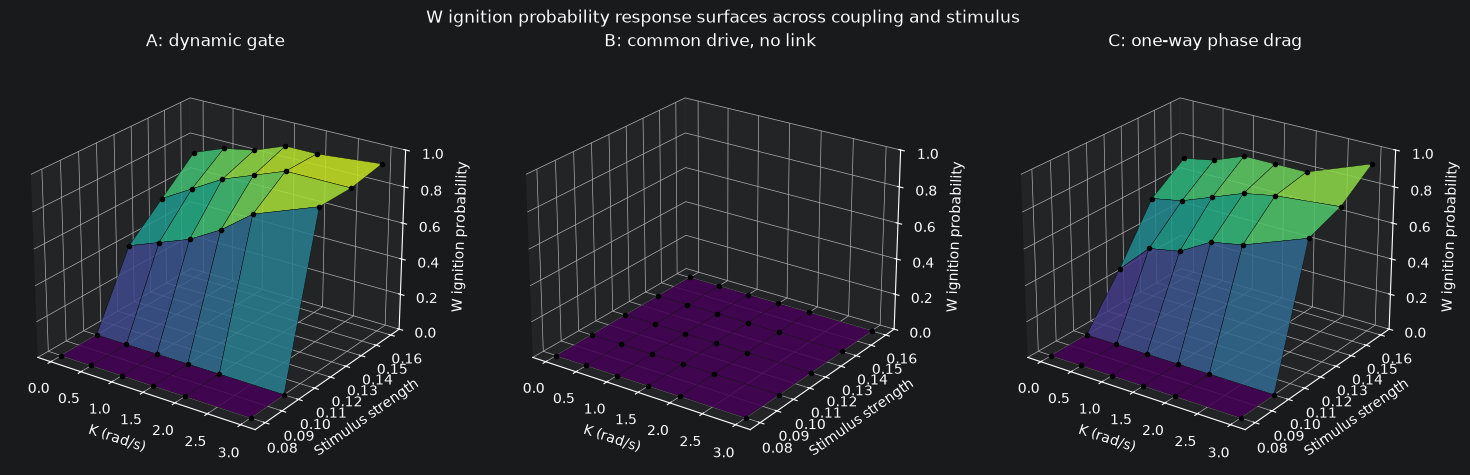

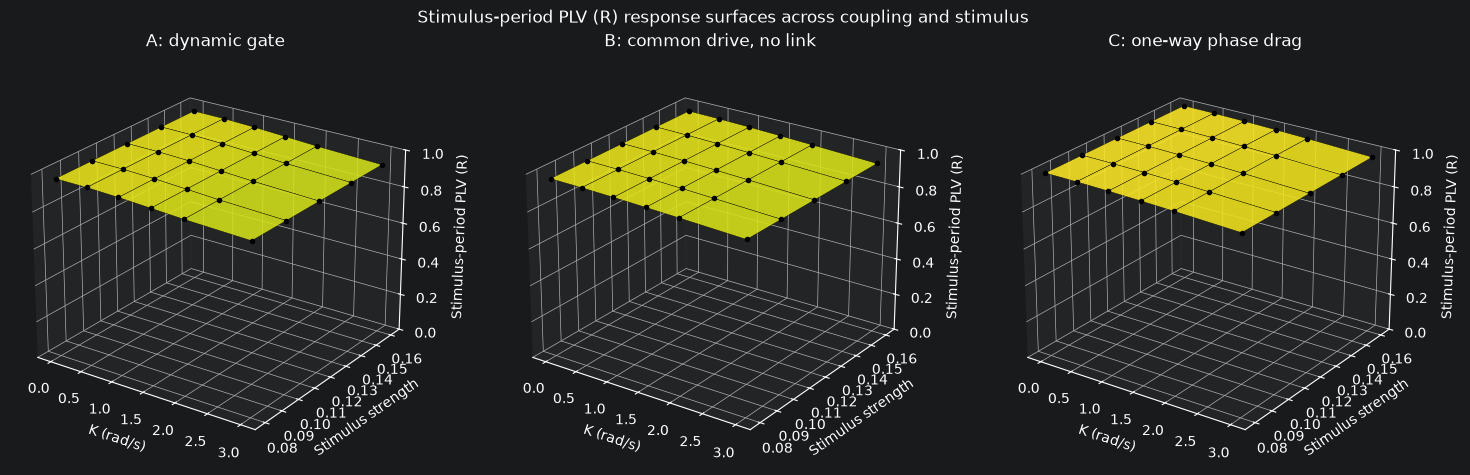

In [7]:
if 'parameter_map' not in globals():
    cached_trials = project_root / 'project_experiment' / 'stage1_ctc_parameter_map_trials.csv'
    if cached_trials.exists():
        map_trials = pd.read_csv(cached_trials)
        parameter_map = map_trials.groupby(['condition', 'stimulus_drive', 'K_rad_s']).agg(
            R_PLV=('R_PLV', 'mean'), ignition_probability=('W_ignited', 'mean'),
            mean_rW_hz=('mean_rW_hz', 'mean')).reset_index()
    else:
        raise RuntimeError('Run the optional K × stimulus parameter map cell first (set RUN_PARAMETER_MAP=True).')

conditions = ['A', 'B', 'C']
condition_labels = {'A': 'A: dynamic gate', 'B': 'B: common drive, no link', 'C': 'C: one-way phase drag'}
def _plot_parameter_surfaces(value_col, z_label, filename):
    fig = plt.figure(figsize=(15, 4.8))
    for panel, condition in enumerate(conditions, start=1):
        subset = parameter_map[parameter_map['condition'] == condition]
        z = subset.pivot(index='stimulus_drive', columns='K_rad_s', values=value_col).sort_index()
        k_grid, drive_grid = np.meshgrid(z.columns.to_numpy(float), z.index.to_numpy(float))
        ax = fig.add_subplot(1, 3, panel, projection='3d')
        ax.plot_surface(k_grid, drive_grid, z.to_numpy(float), cmap='viridis', vmin=0, vmax=1,
                        edgecolor='k', linewidth=0.25, alpha=0.88)
        ax.scatter(k_grid, drive_grid, z.to_numpy(float), color='black', s=9, depthshade=False)
        ax.set(xlabel='K (rad/s)', ylabel='Stimulus strength', zlabel=z_label,
               title=condition_labels[condition], zlim=(0, 1))
        ax.view_init(elev=24, azim=-55)
    fig.suptitle(f'{z_label} response surfaces across coupling and stimulus')
    fig.tight_layout()
    fig.savefig(project_root / 'project_experiment' / filename, dpi=180, bbox_inches='tight')
    plt.show()

_plot_parameter_surfaces('ignition_probability', 'W ignition probability', 'stage1_ctc_ignition_surfaces.png')
_plot_parameter_surfaces('R_PLV', 'Stimulus-period PLV (R)', 'stage1_ctc_plv_surfaces.png')


## Stage 1.4 — Independent confirmation of the candidate window

This replication uses fresh paired seeds (101–200), with 100 trials for each selected K × stimulus combination. The primary comparison is A vs C for W ignition; A vs B is the common-drive/no-link control. Holm correction is applied across the four A-vs-C primary comparisons. The previous exploratory seeds are not reused.


In [ ]:
# Fresh-seed replication of the candidate window. This cell takes about 1–3 minutes.
replication_K = [2.0, 3.0]
replication_drives = [0.12, 0.14]
replication_seeds = np.arange(101, 201)  # independent of the discovery seeds 1–50
replication_gate = phase_gate
replication_rows = []
replication_total = len(replication_K) * len(replication_drives) * len(replication_seeds) * 3
try:
    replication_progress = tqdm(total=replication_total, desc='Independent CTC replication', unit='run')
except NameError:
    replication_progress = None

for drive in replication_drives:
    for K in replication_K:
        for seed in replication_seeds:
            for condition, label, gate in (
                ('A', 'A_dynamic_gate', replication_gate),
                ('B', 'B_common_drive_no_link', 0.0),
                ('C', 'C_one_way_phase_drag', replication_gate),
            ):
                result = simulate_stage0(condition, seed=int(seed), params={
                    **stage1_params, 'stimulus_drive': drive,
                    'phase_coupling_rad_s': K, 'phase_gate_strength': gate,
                })
                row = _record_trial(result, label, K, int(seed), gate,
                                    stage1_params['stim_on_ms'], stage1_params['stim_off_ms'])
                row['stimulus_drive'] = drive
                replication_rows.append(row)
                if replication_progress is not None:
                    replication_progress.update(1)
if replication_progress is not None:
    replication_progress.close()

replication_trials = pd.DataFrame(replication_rows)
replication_trials.to_csv(project_root / 'project_experiment' / 'stage1_ctc_replication_trials.csv', index=False)
replication_summary = replication_trials.groupby(['stimulus_drive', 'K_rad_s', 'condition']).agg(
    n=('seed', 'count'), ignition_probability=('W_ignited', 'mean'),
    mean_R=('R_PLV_during_stim', 'mean'), mean_MI_corrected_bits=('MI_rates_corrected_bits', 'mean'),
    mean_rW_during_hz=('mean_rW_during_hz', 'mean'), mean_peak_rW_hz=('max_rW_hz', 'mean'),
).reset_index()
replication_summary.to_csv(project_root / 'project_experiment' / 'stage1_ctc_replication_summary.csv', index=False)

# Paired bootstrap CIs and one-sided exact McNemar/binomial tests for ignition.
from scipy.stats import binomtest
replication_contrasts = []
for drive in replication_drives:
    for K in replication_K:
        block = replication_trials[(replication_trials.stimulus_drive == drive) & (replication_trials.K_rad_s == K)]
        for control in ('C_one_way_phase_drag', 'B_common_drive_no_link'):
            pair = block[block.condition.isin(['A_dynamic_gate', control])].pivot(
                index='seed', columns='condition', values='W_ignited').astype(bool)
            delta = pair['A_dynamic_gate'].astype(float).to_numpy() - pair[control].astype(float).to_numpy()
            boot_rng = np.random.default_rng(20270000 + int(drive * 1000) + int(K * 100) + len(control))
            draws = boot_rng.choice(delta, size=(10000, len(delta)), replace=True).mean(axis=1)
            a_only = int((delta > 0).sum())
            control_only = int((delta < 0).sum())
            discordant = a_only + control_only
            p_one_sided = float(binomtest(a_only, discordant, p=0.5, alternative='greater').pvalue) if discordant else 1.0
            replication_contrasts.append({
                'stimulus_drive': drive, 'K_rad_s': K, 'control': control,
                'A_ignition_probability': float(pair['A_dynamic_gate'].mean()),
                'control_ignition_probability': float(pair[control].mean()),
                'paired_difference_A_minus_control': float(delta.mean()),
                'paired_bootstrap_95ci_low': float(np.quantile(draws, .025)),
                'paired_bootstrap_95ci_high': float(np.quantile(draws, .975)),
                'A_only_pairs': a_only, 'control_only_pairs': control_only,
                'mcnemar_one_sided_p': p_one_sided,
            })
replication_contrasts = pd.DataFrame(replication_contrasts)

# Holm family-wise correction, separately for the four prespecified A-vs-C primary tests.
def _holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    adjusted = np.empty_like(pvalues)
    running = 0.0
    m = len(pvalues)
    for rank, index in enumerate(order):
        running = max(running, (m - rank) * pvalues[index])
        adjusted[index] = min(1.0, running)
    return adjusted
primary_mask = replication_contrasts['control'].eq('C_one_way_phase_drag')
replication_contrasts['holm_adjusted_p_primary_A_vs_C'] = np.nan
replication_contrasts.loc[primary_mask, 'holm_adjusted_p_primary_A_vs_C'] = _holm_adjust(
    replication_contrasts.loc[primary_mask, 'mcnemar_one_sided_p'].to_numpy())
replication_contrasts.to_csv(project_root / 'project_experiment' / 'stage1_ctc_replication_paired_contrasts.csv', index=False)
display(replication_summary.round(3))
display(replication_contrasts.round(4))


### Replication result interpretation

- In the four prespecified candidate combinations, A ignition was **87%, 94%, 93%, and 96%**; C was **65%, 74%, 81%, and 86%**; B was **0%** throughout.
- Paired A–C ignition differences were **10–22 percentage points**. All four one-sided exact paired tests remained significant after Holm correction (adjusted p < 0.007).
- Thus the candidate window is independently replicated for the model’s ignition outcome. This is evidence that the A configuration performs better than the one-way phase-drag C control here; it does not by itself validate the full CTC theory.
- PLV is higher in C than A, and B also has high PLV despite no ignition. Raw synchrony therefore does not explain the A advantage. Rate MI is also high in B, so this MI estimator is not a directional communication measure and needs separate revision.
- Treat this as confirmation within this two-node mean-field model and parameter window only. The stimulus drive is a model input unit, not pA.


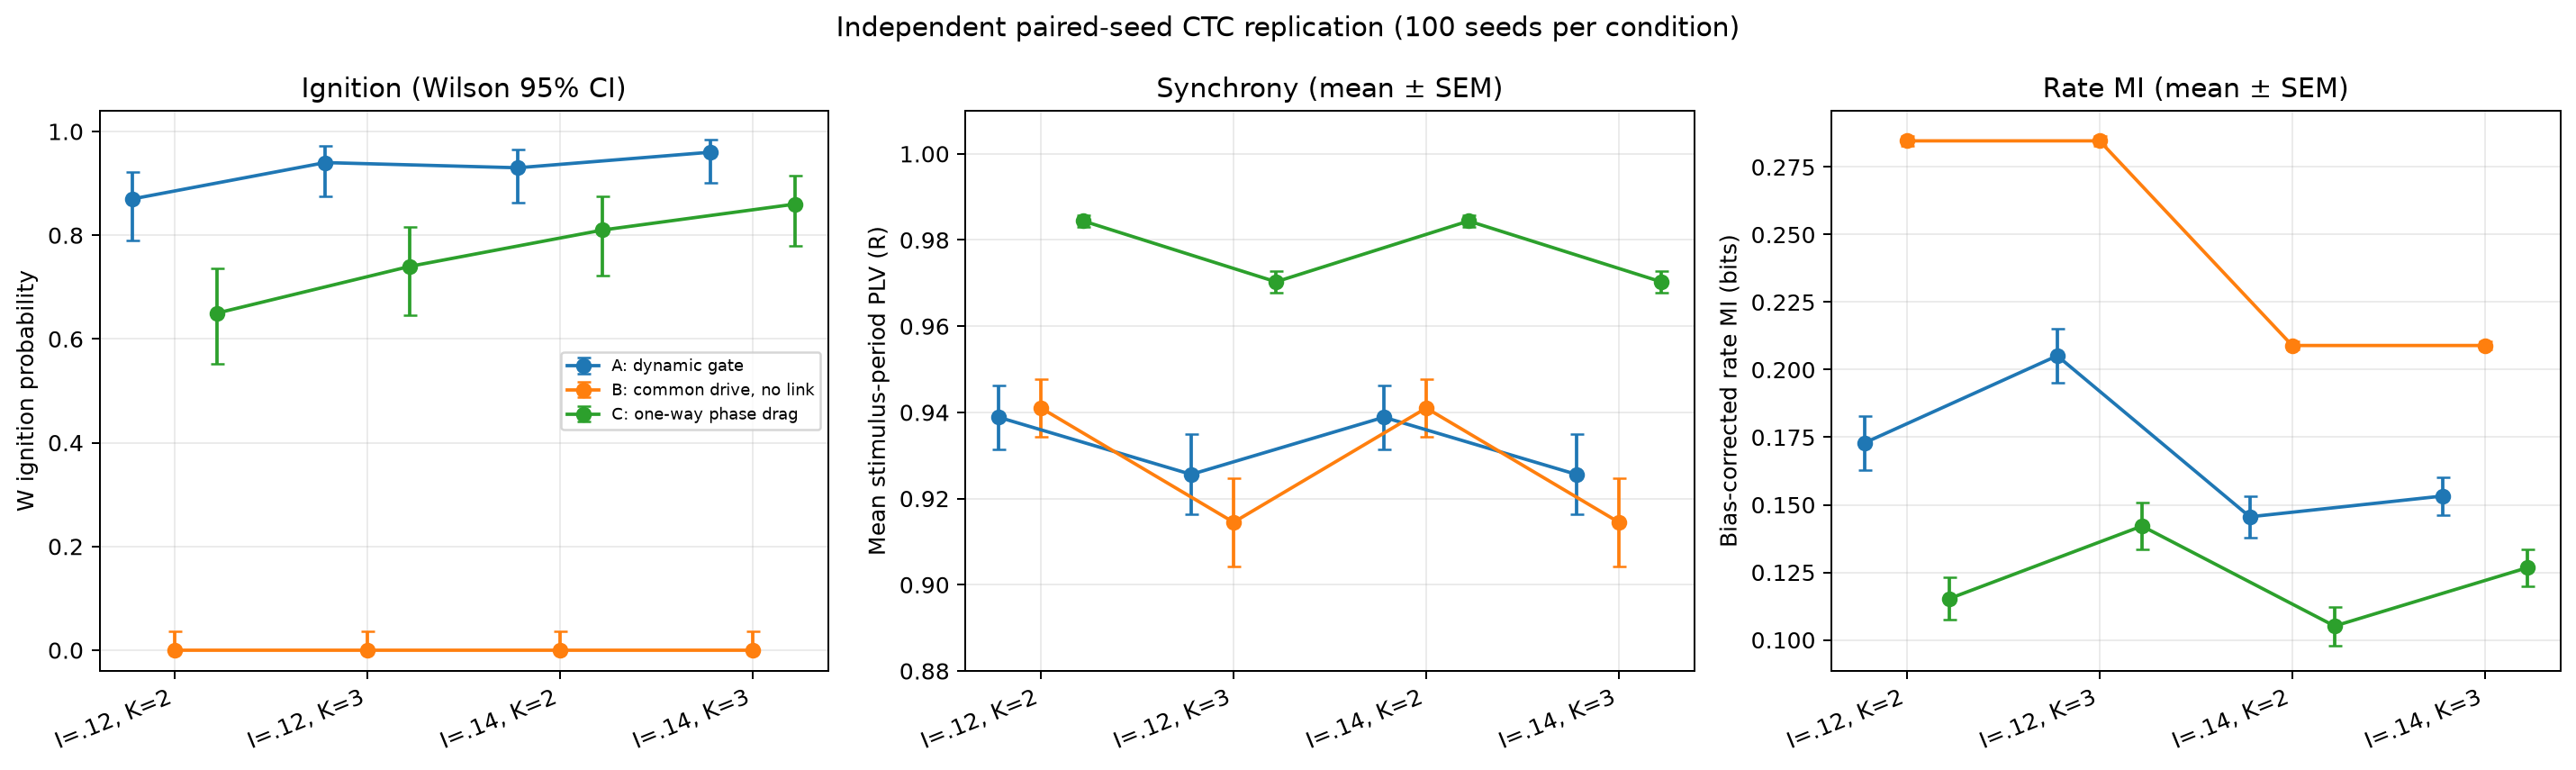

In [1]:
# Recreate the independent replication diagnostic from the saved paired-seed CSV.
replication_trials = pd.read_csv(project_root / 'project_experiment' / 'stage1_ctc_replication_trials.csv')
replication_summary = replication_trials.groupby(['stimulus_drive', 'K_rad_s', 'condition']).agg(
    n=('seed', 'count'), ignition_probability=('W_ignited', 'mean'),
    mean_R=('R_PLV_during_stim', 'mean'), sd_R=('R_PLV_during_stim', 'std'),
    mean_MI=('MI_rates_corrected_bits', 'mean'), sd_MI=('MI_rates_corrected_bits', 'std'),
).reset_index()
# Wilson intervals for binary ignition probabilities.
replication_combos = [(0.12, 2.0), (0.12, 3.0), (0.14, 2.0), (0.14, 3.0)]
replication_conditions = ['A_dynamic_gate', 'B_common_drive_no_link', 'C_one_way_phase_drag']
replication_pretty = {'A_dynamic_gate': 'A: dynamic gate',
                      'B_common_drive_no_link': 'B: common drive, no link',
                      'C_one_way_phase_drag': 'C: one-way phase drag'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
xx = np.arange(len(replication_combos))
replication_offsets = {'A_dynamic_gate': -0.22, 'B_common_drive_no_link': 0.0, 'C_one_way_phase_drag': 0.22}
for condition in replication_conditions:
    group = replication_summary[replication_summary.condition == condition].set_index(['stimulus_drive', 'K_rad_s'])
    probability = np.array([group.loc[key, 'ignition_probability'] for key in replication_combos])
    n = np.array([group.loc[key, 'n'] for key in replication_combos], dtype=float)
    z = 1.96
    denominator = 1 + z*z/n
    center = (probability + z*z/(2*n)) / denominator
    half = z*np.sqrt(probability*(1-probability)/n + z*z/(4*n*n)) / denominator
    axes[0].errorbar(xx + replication_offsets[condition], probability,
        yerr=np.vstack([probability-(center-half), (center+half)-probability]),
        fmt='o-', capsize=3, label=replication_pretty[condition])
    mean_r = np.array([group.loc[key, 'mean_R'] for key in replication_combos])
    sem_r = np.array([group.loc[key, 'sd_R']/np.sqrt(group.loc[key, 'n']) for key in replication_combos])
    axes[1].errorbar(xx + replication_offsets[condition], mean_r, yerr=sem_r, fmt='o-', capsize=3,
                     label=replication_pretty[condition])
    mean_mi = np.array([group.loc[key, 'mean_MI'] for key in replication_combos])
    sem_mi = np.array([group.loc[key, 'sd_MI']/np.sqrt(group.loc[key, 'n']) for key in replication_combos])
    axes[2].errorbar(xx + replication_offsets[condition], mean_mi, yerr=sem_mi, fmt='o-', capsize=3,
                     label=replication_pretty[condition])
replication_labels = ['I=.12, K=2', 'I=.12, K=3', 'I=.14, K=2', 'I=.14, K=3']
axes[0].set_ylabel('W ignition probability'); axes[0].set_ylim(-.04, 1.04); axes[0].set_title('Ignition (Wilson 95% CI)')
axes[1].set_ylabel('Mean stimulus-period PLV (R)'); axes[1].set_ylim(.88, 1.01); axes[1].set_title('Synchrony (mean ± SEM)')
axes[2].set_ylabel('Bias-corrected rate MI (bits)'); axes[2].set_title('Rate MI (mean ± SEM)')
for ax in axes:
    ax.set_xticks(xx, replication_labels, rotation=22, ha='right'); ax.grid(alpha=.25)
axes[0].legend(fontsize=7)
fig.suptitle('Independent paired-seed CTC replication (100 seeds per condition)')
fig.tight_layout()
fig.savefig(project_root / 'project_experiment' / 'stage1_ctc_replication.png', dpi=180, bbox_inches='tight')
plt.show()
